In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

## Load the dataset

In [2]:
df = pd.read_csv("../data/raw/Loan_default.csv")

In [3]:
df.head()

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


## Understand the dataset

In [4]:
df.shape;

(255347, 18)

In [5]:
df.columns

Index(['LoanID', 'Age', 'Income', 'LoanAmount', 'CreditScore',
       'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm',
       'DTIRatio', 'Education', 'EmploymentType', 'MaritalStatus',
       'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner',
       'Default'],
      dtype='object')

In [7]:
df.dtypes

LoanID             object
Age                 int64
Income              int64
LoanAmount          int64
CreditScore         int64
MonthsEmployed      int64
NumCreditLines      int64
InterestRate      float64
LoanTerm            int64
DTIRatio          float64
Education          object
EmploymentType     object
MaritalStatus      object
HasMortgage        object
HasDependents      object
LoanPurpose        object
HasCoSigner        object
Default             int64
dtype: object

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 255347 entries, 0 to 255346
Data columns (total 18 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   LoanID          255347 non-null  object 
 1   Age             255347 non-null  int64  
 2   Income          255347 non-null  int64  
 3   LoanAmount      255347 non-null  int64  
 4   CreditScore     255347 non-null  int64  
 5   MonthsEmployed  255347 non-null  int64  
 6   NumCreditLines  255347 non-null  int64  
 7   InterestRate    255347 non-null  float64
 8   LoanTerm        255347 non-null  int64  
 9   DTIRatio        255347 non-null  float64
 10  Education       255347 non-null  object 
 11  EmploymentType  255347 non-null  object 
 12  MaritalStatus   255347 non-null  object 
 13  HasMortgage     255347 non-null  object 
 14  HasDependents   255347 non-null  object 
 15  LoanPurpose     255347 non-null  object 
 16  HasCoSigner     255347 non-null  object 
 17  Default   

## Statistical summary

In [9]:
df.describe(include="object")

,LoanID,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner
count,255347,255347,255347,255347,255347,255347,255347,255347
unique,255347,4,4,3,2,2,5,2
top,ZTH91CGL0B,Bachelor's,Part-time,Married,Yes,Yes,Business,Yes
freq,1,64366,64161,85302,127677,127742,51298,127701


In [10]:
df.describe()

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Default
count,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000
mean,43.498306,82499.304597,127578.865512,574.264346,59.541976,2.501036,13.492773,36.025894,0.500212,0.116128
std,14.990258,38963.013729,70840.706142,158.903867,34.643376,1.117018,6.636443,16.969330,0.230917,0.320379
min,18.000000,15000.000000,5000.000000,300.000000,0.000000,1.000000,2.000000,12.000000,0.100000,0.000000
25%,31.000000,48825.500000,66156.000000,437.000000,30.000000,2.000000,7.770000,24.000000,0.300000,0.000000
50%,43.000000,82466.000000,127556.000000,574.000000,60.000000,2.000000,13.460000,36.000000,0.500000,0.000000
75%,56.000000,116219.000000,188985.000000,712.000000,90.000000,3.000000,19.250000,48.000000,0.700000,0.000000
max,69.000000,149999.000000,249999.000000,849.000000,119.000000,4.000000,25.000000,60.000000,0.900000,1.000000


## Check missing values

In [11]:
missing_values = df.isnull().sum()

missing_values

LoanID            0
Age               0
Income            0
LoanAmount        0
CreditScore       0
MonthsEmployed    0
NumCreditLines    0
InterestRate      0
LoanTerm          0
DTIRatio          0
Education         0
EmploymentType    0
MaritalStatus     0
HasMortgage       0
HasDependents     0
LoanPurpose       0
HasCoSigner       0
Default           0
dtype: int64

In [12]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing_Count": missing_values,
    "Missing_Percentage": missing_percentage
})

missing_summary

,Missing_Count,Missing_Percentage
LoanID,0,0.0
Age,0,0.0
Income,0,0.0
LoanAmount,0,0.0
CreditScore,0,0.0
MonthsEmployed,0,0.0
NumCreditLines,0,0.0
InterestRate,0,0.0
LoanTerm,0,0.0
DTIRatio,0,0.0


## Check duplicate rows

In [13]:
df.duplicated().sum()

np.int64(0)

## Check the target variable

In [14]:
df["Default"].value_counts()

Default
0    225694
1     29653
Name: count, dtype: int64

In [15]:
df["Default"].value_counts(normalize=True) * 100

Default
0    88.387175
1    11.612825
Name: proportion, dtype: float64

In [16]:
target_summary = pd.DataFrame({
    "Count": df["Default"].value_counts(),
    "Percentage": df["Default"].value_counts(normalize=True) * 100
})

target_summary

,Count,Percentage
Default,,
0,225694,88.387175
1,29653,11.612825


## Visualize target imbalance

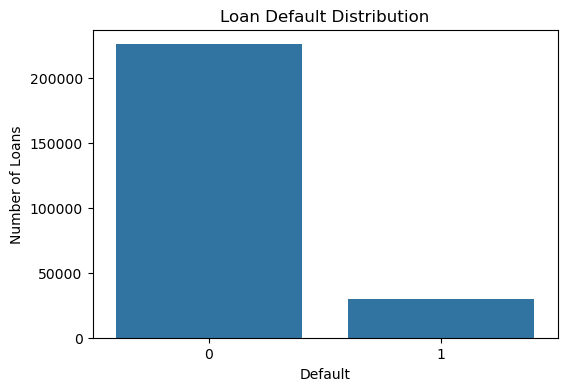

In [17]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Default")

plt.title("Loan Default Distribution")
plt.xlabel("Default")
plt.ylabel("Number of Loans")

plt.show()

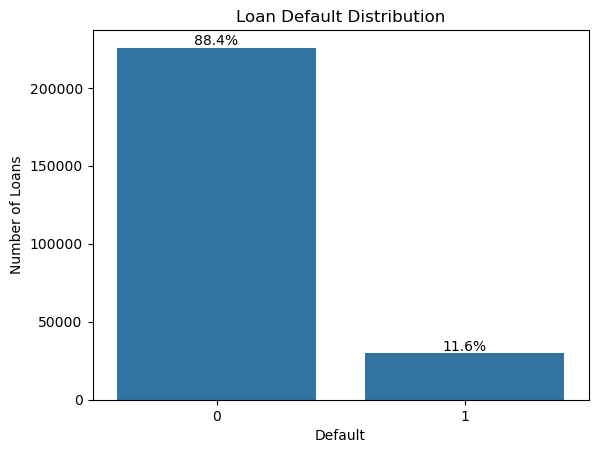

In [18]:
ax = sns.countplot(data=df, x="Default")

total = len(df)

for container in ax.containers:
    labels = [
        f"{value / total:.1%}"
        for value in container.datavalues
    ]
    ax.bar_label(container, labels=labels)

plt.title("Loan Default Distribution")
plt.xlabel("Default")
plt.ylabel("Number of Loans")

plt.show()

## Check unique values

In [19]:
for column in df.columns:
    print("\n", column)
    print(df[column].unique()[:20])


 LoanID
['I38PQUQS96' 'HPSK72WA7R' 'C1OZ6DPJ8Y' 'V2KKSFM3UN' 'EY08JDHTZP'
 'A9S62RQ7US' 'H8GXPAOS71' '0HGZQKJ36W' '1R0N3LGNRJ' 'CM9L1GTT2P'
 'IA35XVH6ZO' 'Y8UETC3LSG' 'RM6QSRHIYP' 'GX5YQOGROM' 'X0BVPZLDC0'
 'O5DM5MPPNA' 'ZDDRGVTEXS' '9V0FJW7QPB' 'O1IKKLC69B' 'F7487UU2BF']

 Age
[56 69 46 32 60 25 38 36 40 28 41 53 57 20 39 19 61 47 55 50]

 Income
[ 85994  50432  84208  31713  20437  90298 111188 126802  42053 132784
 140466 149227  23265 117550 139699  74064 119704  33015  40718 123419]

 LoanAmount
[ 50587 124440 129188  44799   9139  90448 177025 155511  92357 228510
 163781 139759  63527  95744  88143 230883  25697  10889  78515 161146]

 CreditScore
[520 458 451 743 633 720 429 531 827 480 652 375 829 395 635 432 313 811
 319 376]

 MonthsEmployed
[ 80  15  26   0   8  18  67  83 114  94  56  87 112  31  49 106 119  65
  96  55]

 NumCreditLines
[4 1 3 2]

 InterestRate
[15.23  4.81 21.17  7.07  6.51 22.72 19.11  8.15 23.94  9.09  9.08  5.84
  9.73  3.58  5.63  5.    9.63 13.56 1

In [20]:
categorical_columns = df.select_dtypes(include="object").columns

for column in categorical_columns:
    print(f"\n{column}")
    print(df[column].value_counts())


LoanID
LoanID
ZTH91CGL0B    1
I38PQUQS96    1
HPSK72WA7R    1
QU29Z1EVQI    1
QXBHNXNA9X    1
             ..
0HGZQKJ36W    1
H8GXPAOS71    1
A9S62RQ7US    1
EY08JDHTZP    1
V2KKSFM3UN    1
Name: count, Length: 255347, dtype: int64

Education
Education
Bachelor's     64366
High School    63903
Master's       63541
PhD            63537
Name: count, dtype: int64

EmploymentType
EmploymentType
Part-time        64161
Unemployed       63824
Self-employed    63706
Full-time        63656
Name: count, dtype: int64

MaritalStatus
MaritalStatus
Married     85302
Divorced    85033
Single      85012
Name: count, dtype: int64

HasMortgage
HasMortgage
Yes    127677
No     127670
Name: count, dtype: int64

HasDependents
HasDependents
Yes    127742
No     127605
Name: count, dtype: int64

LoanPurpose
LoanPurpose
Business     51298
Home         51286
Education    51005
Other        50914
Auto         50844
Name: count, dtype: int64

HasCoSigner
HasCoSigner
Yes    127701
No     127646
Name: count, dtyp

## Check logical ranges

##### Age

In [21]:
df["Age"].describe()

count    255347.000000
mean         43.498306
std          14.990258
min          18.000000
25%          31.000000
50%          43.000000
75%          56.000000
max          69.000000
Name: Age, dtype: float64

In [22]:
(df["Age"] < 18).sum()

np.int64(0)

In [23]:
(df["Age"] > 100).sum()

np.int64(0)

##### Income

In [24]:
(df["Income"] <= 0).sum()

np.int64(0)

##### Loan Amount

In [25]:
(df["LoanAmount"] <= 0).sum()

np.int64(0)

##### Credit Score

In [26]:
(df["CreditScore"] < 300).sum()

np.int64(0)

In [27]:
(df["CreditScore"] < 300).sum()

np.int64(0)

##### Interest Rate

In [28]:
(df["InterestRate"] <= 0).sum()

np.int64(0)

In [29]:
(df["InterestRate"] > 100).sum()

np.int64(0)

##### DTI

In [30]:
(df["DTIRatio"] < 0).sum()

np.int64(0)

In [32]:
(df["DTIRatio"] > 1).sum()

np.int64(0)

## Check ID uniqueness

In [33]:
df["LoanID"].nunique()

255347

In [34]:
len(df)

255347

In [35]:
X = df.drop(columns=["Default", "LoanID"])
y = df["Default"]

## Numerical feature distributions

In [36]:
numerical_columns = df.select_dtypes(include=np.number).columns

numerical_columns

Index(['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed',
       'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'Default'],
      dtype='object')

In [37]:
numerical_features = [
    column for column in numerical_columns
    if column != "Default"
]

numerical_features

['Age',
 'Income',
 'LoanAmount',
 'CreditScore',
 'MonthsEmployed',
 'NumCreditLines',
 'InterestRate',
 'LoanTerm',
 'DTIRatio']

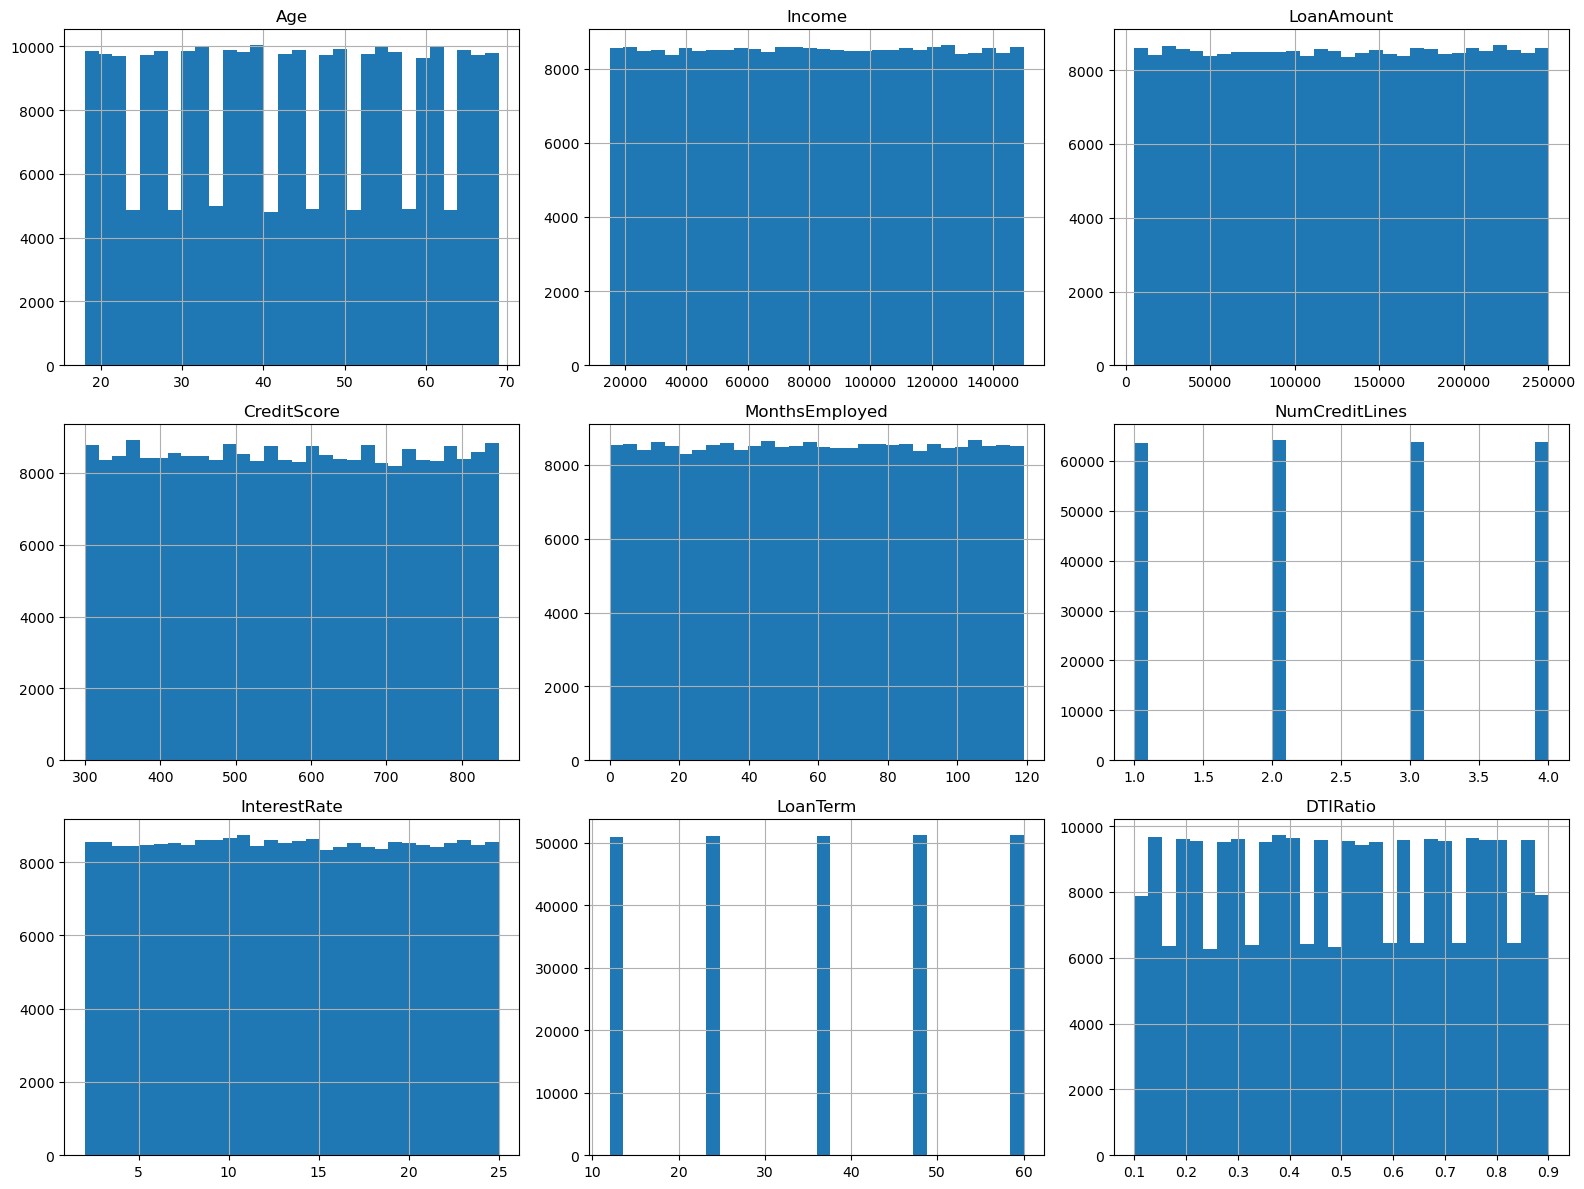

In [38]:
df[numerical_features].hist(
    figsize=(16, 12),
    bins=30
)

plt.tight_layout()
plt.show()

## Boxplots for outlier investigation

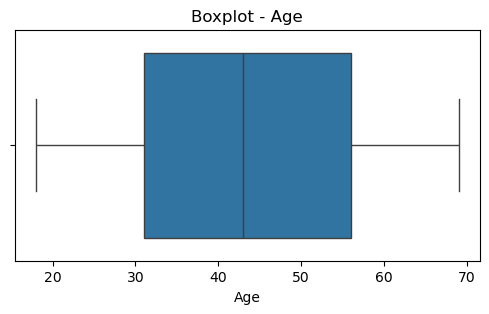

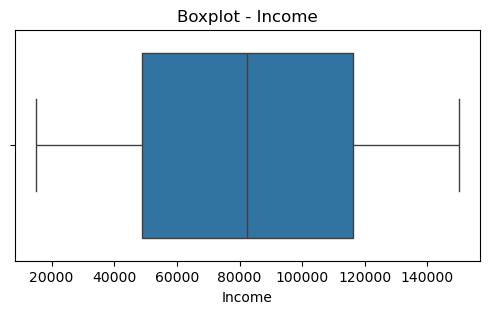

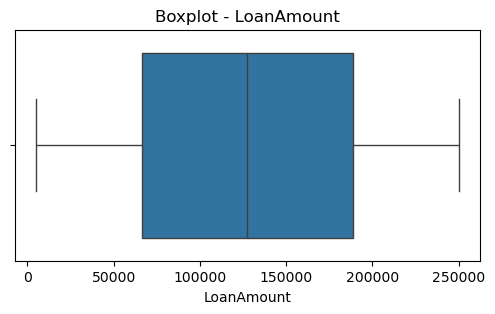

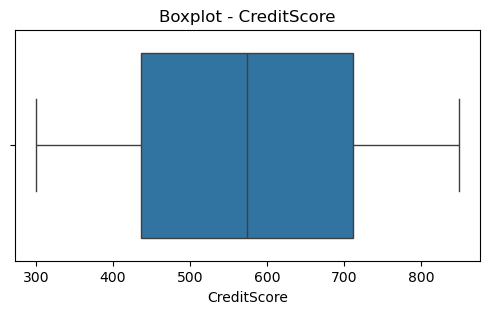

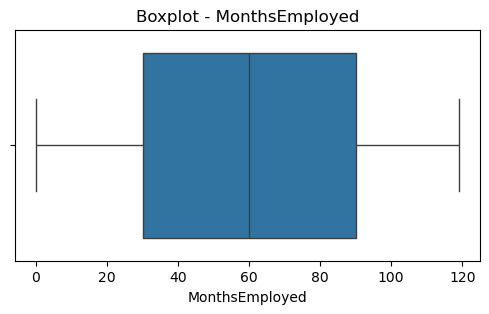

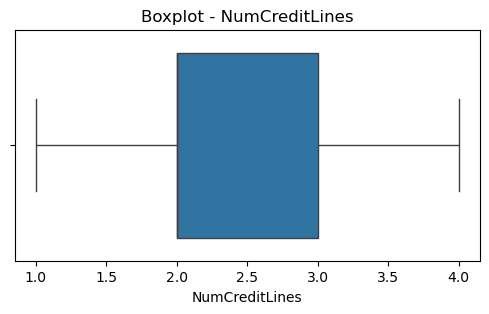

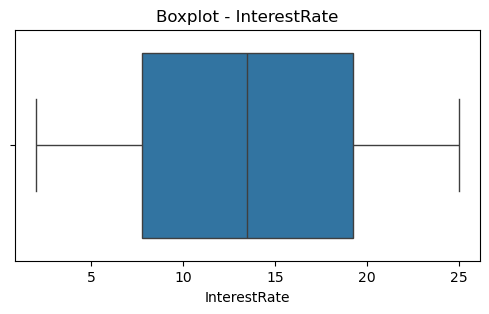

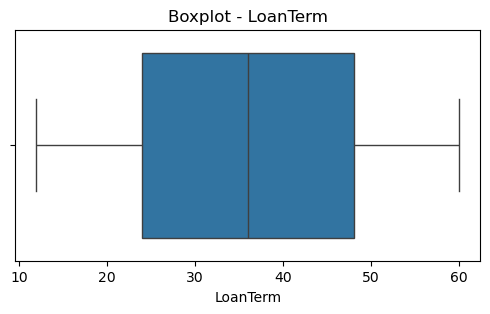

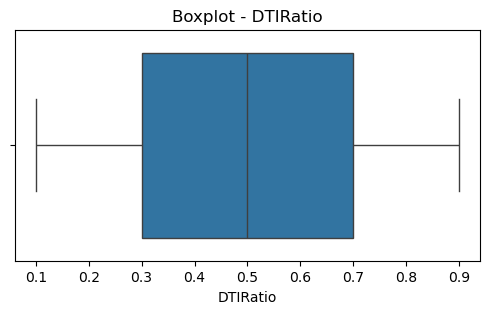

In [39]:
for column in numerical_features:
    plt.figure(figsize=(6, 3))

    sns.boxplot(x=df[column])

    plt.title(f"Boxplot - {column}")

    plt.show()

## Default rate by age

In [40]:
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[17, 28, 38, 49, 59, 69],
    labels=["18-28", "29-38", "39-49", "50-59", "60-69"]
)

In [41]:
age_default = (
    df.groupby("AgeGroup", observed=True)["Default"]
    .mean() * 100
)

age_default

AgeGroup
18-28    20.030507
29-38    14.666991
39-49    10.234270
50-59     7.316527
60-69     5.127210
Name: Default, dtype: float64

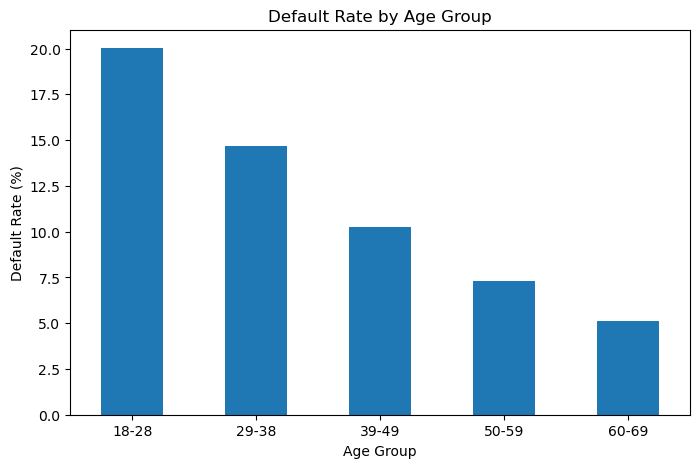

In [42]:
age_default.plot(kind="bar", figsize=(8, 5))

plt.title("Default Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)

plt.show()

## Income vs default

In [43]:
df["IncomeGroup"] = pd.qcut(
    df["Income"],
    q=5,
    labels=["Q1", "Q2", "Q3", "Q4", "Q5"]
)

In [44]:
income_default = (
    df.groupby("IncomeGroup", observed=True)["Default"]
    .mean() * 100
)

income_default

IncomeGroup
Q1    18.538534
Q2    11.380904
Q3     9.863319
Q4     9.306834
Q5     8.974133
Name: Default, dtype: float64

## Loan amount vs default

In [45]:
df["LoanAmountGroup"] = pd.qcut(
    df["LoanAmount"],
    q=5,
    labels=["Q1", "Q2", "Q3", "Q4", "Q5"]
)

In [46]:
loan_default = (
    df.groupby("LoanAmountGroup", observed=True)["Default"]
    .mean() * 100
)

loan_default

LoanAmountGroup
Q1     8.049736
Q2     9.665355
Q3    11.196616
Q4    13.336597
Q5    15.815857
Name: Default, dtype: float64

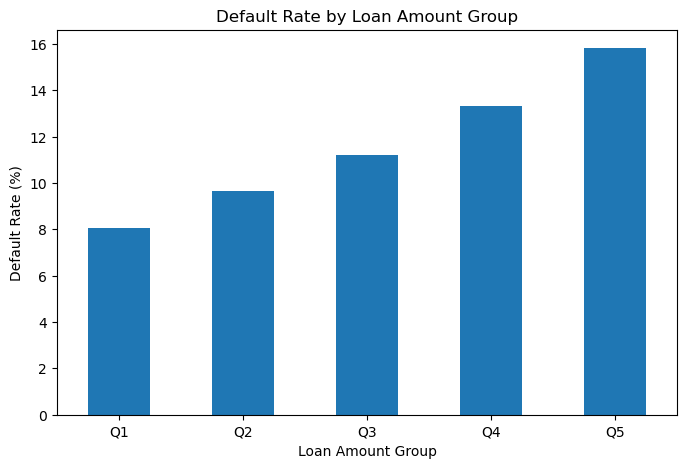

In [47]:
loan_default.plot(kind="bar", figsize=(8, 5))

plt.title("Default Rate by Loan Amount Group")
plt.xlabel("Loan Amount Group")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)

plt.show()

## Credit score vs default

In [49]:
df["CreditScoreGroup"] = pd.qcut(
    df["CreditScore"],
    q=5,
    labels=["Q1", "Q2", "Q3", "Q4", "Q5"]
)

credit_default = (
    df.groupby("CreditScoreGroup", observed=True)["Default"]
    .mean() * 100
)

credit_default

CreditScoreGroup
Q1    13.207033
Q2    12.227783
Q3    11.597529
Q4    10.846157
Q5    10.167221
Name: Default, dtype: float64

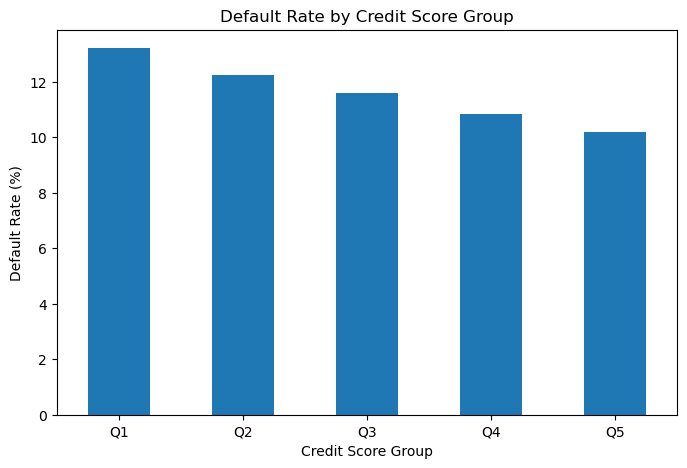

In [50]:
credit_default.plot(kind="bar", figsize=(8, 5))

plt.title("Default Rate by Credit Score Group")
plt.xlabel("Credit Score Group")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)

plt.show()

## Interest rate vs default

In [51]:
df["InterestRateGroup"] = pd.qcut(
    df["InterestRate"],
    q=5,
    labels=["Q1", "Q2", "Q3", "Q4", "Q5"]
)

interest_default = (
    df.groupby("InterestRateGroup", observed=True)["Default"]
    .mean() * 100
)

interest_default

InterestRateGroup
Q1     6.311221
Q2     8.431660
Q3    11.069720
Q4    14.228120
Q5    18.040984
Name: Default, dtype: float64

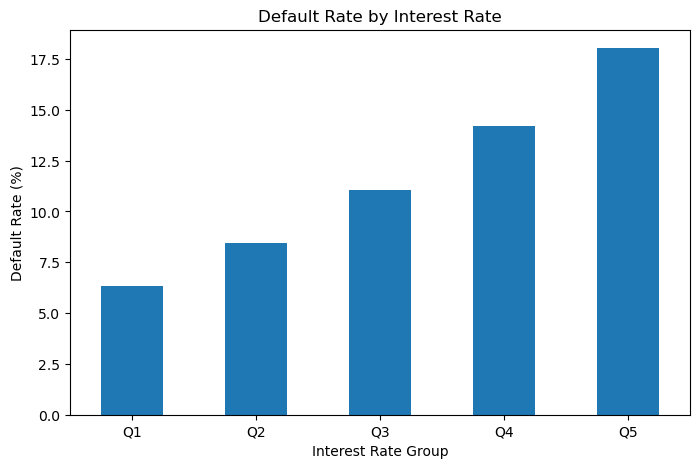

In [52]:
interest_default.plot(kind="bar", figsize=(8, 5))

plt.title("Default Rate by Interest Rate")
plt.xlabel("Interest Rate Group")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)

plt.show()

## Employment vs default

In [53]:
employment_default = (
    df.groupby("EmploymentType")["Default"]
    .mean()
    .sort_values(ascending=False) * 100
)

employment_default

EmploymentType
Unemployed       13.552895
Part-time        11.965213
Self-employed    11.462029
Full-time         9.463366
Name: Default, dtype: float64

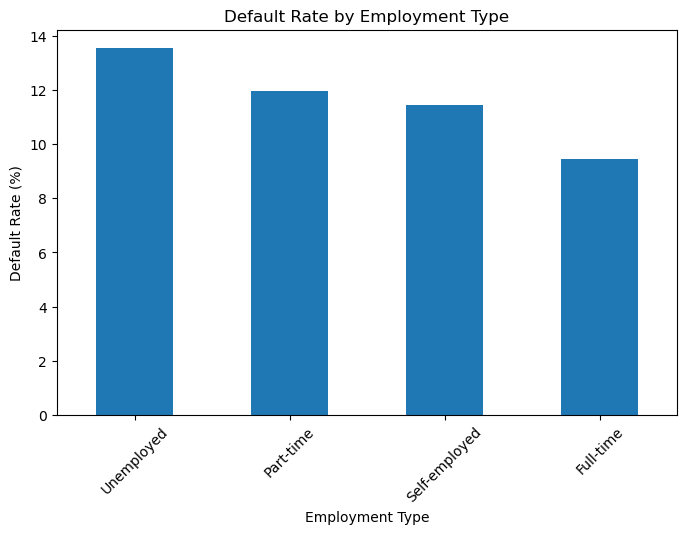

In [54]:
employment_default.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Default Rate by Employment Type")
plt.xlabel("Employment Type")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=45)

plt.show()

## Loan purpose vs default

In [56]:
purpose_default = (
    df.groupby("LoanPurpose")["Default"]
    .mean()
    .sort_values(ascending=False) * 100
)

purpose_default

LoanPurpose
Business     12.326017
Auto         11.881441
Education    11.838055
Other        11.788506
Home         10.234762
Name: Default, dtype: float64

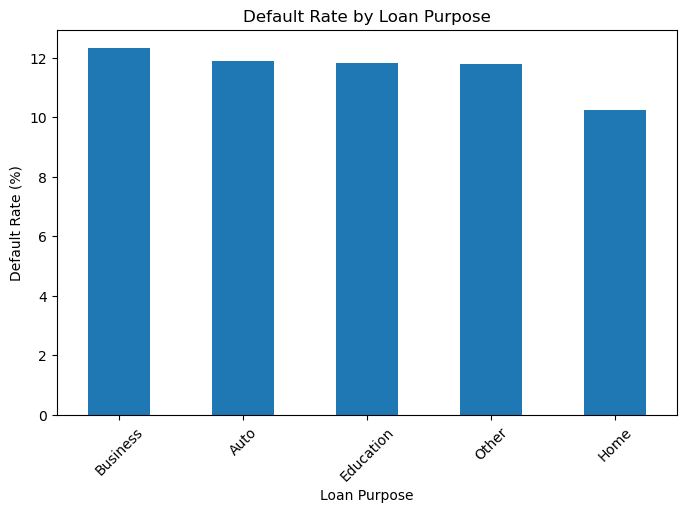

In [57]:
purpose_default.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Default Rate by Loan Purpose")
plt.xlabel("Loan Purpose")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=45)

plt.show()

## Co-signer vs default

In [58]:
cosigner_default = (
    df.groupby("HasCoSigner")["Default"]
    .mean() * 100
)

cosigner_default

HasCoSigner
No     12.866051
Yes    10.360138
Name: Default, dtype: float64

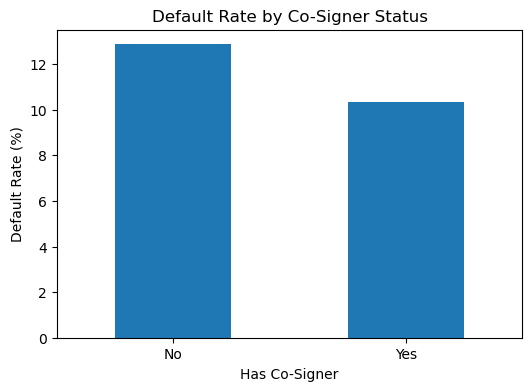

In [59]:
cosigner_default.plot(
    kind="bar",
    figsize=(6, 4)
)

plt.title("Default Rate by Co-Signer Status")
plt.xlabel("Has Co-Signer")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)

plt.show()

## Correlation analysis

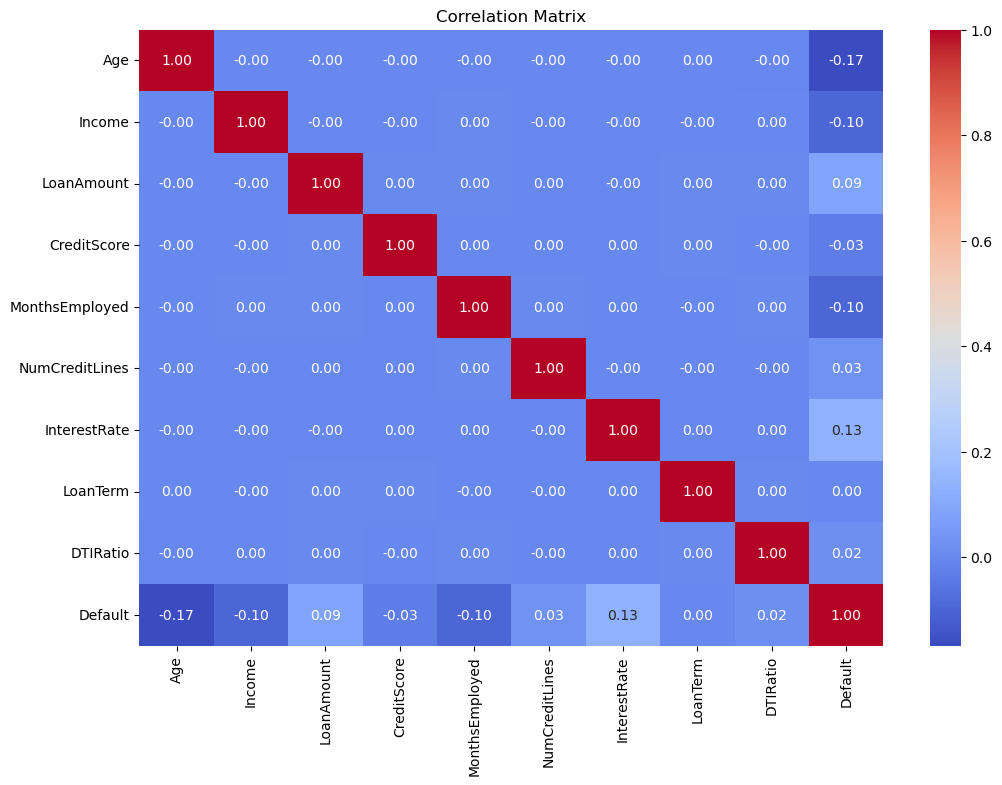

In [60]:
correlation = df[numerical_features + ["Default"]].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Matrix")

plt.show()

## Create a clean EDA summary

In [61]:
eda_summary = pd.DataFrame({
    "Feature": [
        "Age",
        "Income",
        "Loan Amount",
        "Credit Score",
        "Months Employed",
        "Interest Rate",
        "DTI Ratio",
        "Employment Type",
        "Loan Purpose",
        "Co-Signer"
    ],
    "Observation": [
        "Younger groups show higher observed default rates",
        "Lower-income groups show higher observed default rates",
        "Higher loan amounts show higher observed default rates",
        "Higher credit scores show somewhat lower default rates",
        "Shorter employment history shows higher default rates",
        "Higher interest rates show higher observed default rates",
        "Higher DTI shows a modest increase in default rate",
        "Default rates differ across employment categories",
        "Default rates vary across loan purposes",
        "Borrowers with co-signers show lower observed default rates"
    ]
})

eda_summary

,Feature,Observation
0,Age,Younger groups show higher observed default rates
1,Income,Lower-income groups show higher observed defau...
2,Loan Amount,Higher loan amounts show higher observed defau...
3,Credit Score,Higher credit scores show somewhat lower defau...
4,Months Employed,Shorter employment history shows higher defaul...
5,Interest Rate,Higher interest rates show higher observed def...
6,DTI Ratio,Higher DTI shows a modest increase in default ...
7,Employment Type,Default rates differ across employment categories
8,Loan Purpose,Default rates vary across loan purposes
9,Co-Signer,Borrowers with co-signers show lower observed ...


In [62]:
eda_columns = [
    "AgeGroup",
    "IncomeGroup",
    "LoanAmountGroup",
    "CreditScoreGroup",
    "InterestRateGroup"
]

df.drop(columns=eda_columns, inplace=True)